In [6]:
import numpy as np

dati = np.genfromtxt("dati_fit_interferenza.csv", delimiter=",", names=True)
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

Numero di punti totali (N): 161
Intervallo di x: [-5.000, 5.000] mm
Intervallo di y: [6.000, 524.000] u.a.
Intervallo di sigma_y: [2.449, 22.891] u.a.


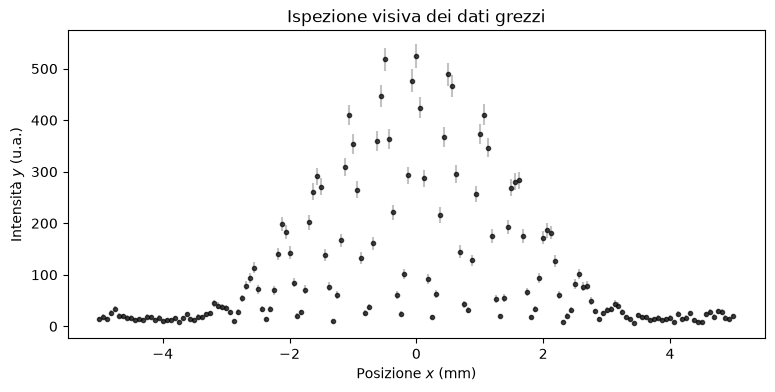

In [12]:
assert (
    len(x) == len(y) == len(sigma_y)
), "Errore: gli array hanno lunghezze differenti!"
assert np.all(
    np.isfinite(x) & np.isfinite(y) & np.isfinite(sigma_y)
), "Errore: presenti valori non finiti (NaN o Inf)!"
assert np.all(sigma_y > 0), "Errore: trovate incertezze non positive!"
assert np.all(np.diff(x) > 0
), "Errore: le posizioni x non sono ordinate in modo crescente!"

print(f"Numero di punti totali (N): {len(x)}")
print(f"Intervallo di x: [{x.min():.3f}, {x.max():.3f}] mm")
print(f"Intervallo di y: [{y.min():.3f}, {y.max():.3f}] u.a.")
print(f"Intervallo di sigma_y: [{sigma_y.min():.3f}, {sigma_y.max():.3f}] u.a.")

plt.figure(figsize=(9, 4))
plt.errorbar(
    x,
    y,
    yerr=sigma_y,
    fmt="o",
    markersize=3,
    color="black",
    ecolor="darkgray",
    alpha=0.7,
)
plt.xlabel("Posizione $x$ (mm)")
plt.ylabel("Intensità $y$ (u.a.)")
plt.title("Ispezione visiva dei dati grezzi")
plt.show()


Numero di punti totali (N): 161
Intervallo di x: [-5.000, 5.000] mm
Intervallo di y: [6.000, 524.000] u.a.
Intervallo di sigma_y: [2.449, 22.891] u.a.


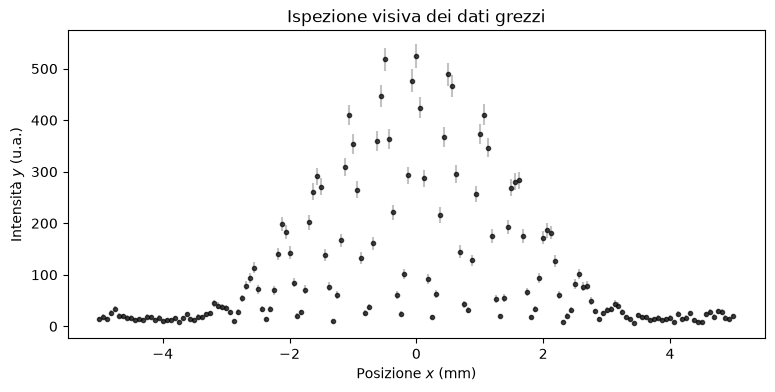

In [12]:
assert (
    len(x) == len(y) == len(sigma_y)
), "Errore: gli array hanno lunghezze differenti!"
assert np.all(
    np.isfinite(x) & np.isfinite(y) & np.isfinite(sigma_y)
), "Errore: presenti valori non finiti (NaN o Inf)!"
assert np.all(sigma_y > 0), "Errore: trovate incertezze non positive!"
assert np.all(np.diff(x) > 0
), "Errore: le posizioni x non sono ordinate in modo crescente!"

print(f"Numero di punti totali (N): {len(x)}")
print(f"Intervallo di x: [{x.min():.3f}, {x.max():.3f}] mm")
print(f"Intervallo di y: [{y.min():.3f}, {y.max():.3f}] u.a.")
print(f"Intervallo di sigma_y: [{sigma_y.min():.3f}, {sigma_y.max():.3f}] u.a.")

plt.figure(figsize=(9, 4))
plt.errorbar(
    x,
    y,
    yerr=sigma_y,
    fmt="o",
    markersize=3,
    color="black",
    ecolor="darkgray",
    alpha=0.7,
)
plt.xlabel("Posizione $x$ (mm)")
plt.ylabel("Intensità $y$ (u.a.)")
plt.title("Ispezione visiva dei dati grezzi")
plt.show()


In [14]:
B_init = np.median(y[(x < x.min() + 0.5) | (x > x.max() - 0.5)])
I0_init = np.max(y) - B_init
alpha_init = 0.5  #Frequenza dell'inviluppo (regolare in base ai dati)
delta_init = 5.0  # Frequenza delle frange d'interferenza

p0 = [B_init, I0_init, alpha_init, delta_init]

lower = [0.0, 0.0, 0.01, 0.1]
upper = [np.inf, np.inf, 10.0, 30.0]

print("\n--- Stime Iniziali ---")
print(f"B^(0) = {B_init:.4f}")
print(f"I0^(0) = {I0_init:.4f}")
print(f"alpha^(0) = {alpha_init:.4f}")
print(f"delta^(0) = {delta_init:.4f}")


--- Stime Iniziali ---
B^(0) = 20.0000
I0^(0) = 504.0000
alpha^(0) = 0.5000
delta^(0) = 5.0000



--- Risultati del Fit Pesato ---
B = 13.4001 ± 0.4471
I_0 = 504.8226 ± 5.1237
\alpha = 0.7995 ± 0.0047
\delta = 5.9976 ± 0.0042


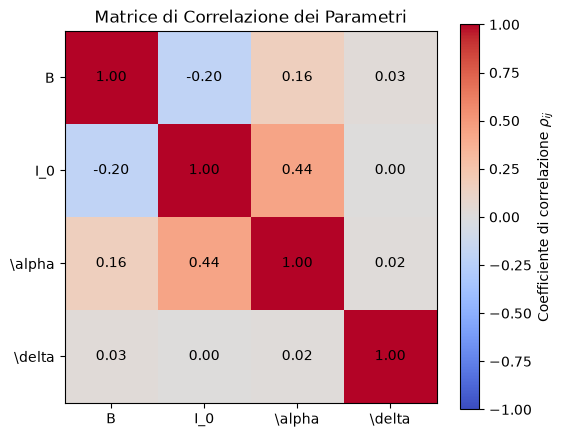

In [19]:
!pip install scipy numpy matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit

def modello(x, B, I_0, alpha, delta):
  sinc = np.ones_like(x, dtype=float)
  nonzero = x != 0
  sinc[nonzero] = np.sin(alpha * x[nonzero]) / (alpha * x[nonzero])
  return B + I_0 * (sinc**2) * (np.cos(delta * x) ** 2) 
    
popt, pcov = curve_fit(
    modello,
    x,
    y,
    p0=p0,
    sigma=sigma_y,
    absolute_sigma=True,
    bounds=(lower, upper),
    maxfev=100000,
)

perr = np.sqrt(np.diag(pcov))
param_names = ["B", "I_0", r"\alpha", r"\delta"]

print("\n--- Risultati del Fit Pesato ---")
for name, val, err in zip(param_names, popt, perr):
  print(f"{name} = {val:.4f} ± {err:.4f}")

# Calcolo matrice di correlazione
corr_matrix = pcov / np.outer(perr, perr)

plt.figure(figsize=(6, 5))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label=r"Coefficiente di correlazione $\rho_{ij}$")
plt.xticks(range(4), param_names)
plt.yticks(range(4), param_names)
plt.title("Matrice di Correlazione dei Parametri")
for i in range(4):
  for j in range(4):
    plt.text(
        j, i, f"{corr_matrix[i, j]:.2f}", ha="center", va="center", color="black"
    )
plt.show()


--- Diagnostica Statistica ---
Chi-quadro ($\chi^2$): 188.47
Gradi di libertà ($\nu$): 157
Chi-quadro ridotto ($\chi^2 / \nu$): 1.200
p-value: 4.3951e-02


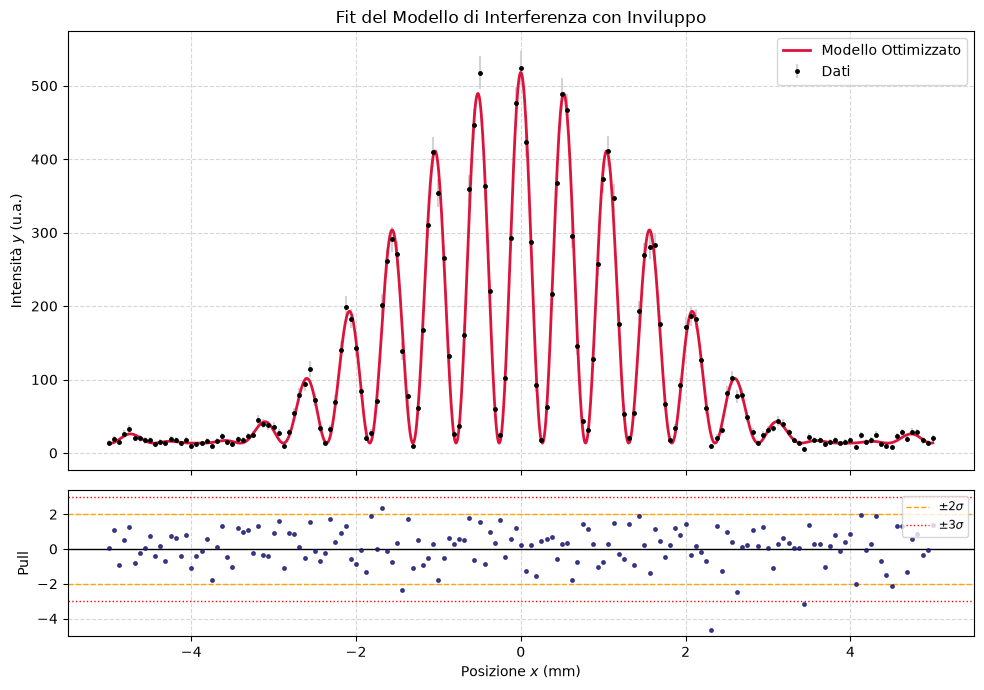

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2

# 1. Calcolo dei residui e dei pull
y_fit = modello(x, *popt)
residuals = y - y_fit
pulls = residuals / sigma_y

# 2. Calcolo degli indicatori statistici
chi2_obs = np.sum(pulls**2)
ndf = len(x) - len(popt)
chi2_red = chi2_obs / ndf
p_value = chi2.sf(chi2_obs, ndf)

# Stampa dei risultati
print("\n--- Diagnostica Statistica ---")
print(rf"Chi-quadro ($\chi^2$): {chi2_obs:.2f}")
print(rf"Gradi di libertà ($\nu$): {ndf}")
print(rf"Chi-quadro ridotto ($\chi^2 / \nu$): {chi2_red:.3f}")
print(rf"p-value: {p_value:.4e}")

# 3. Grafico a due pannelli (Dati + Fit sopra, Pulls sotto)
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)

# Pannello Superiore: Dati e Curva di Fit
ax1.errorbar(
    x,
    y,
    yerr=sigma_y,
    fmt="o",
    markersize=2.5,
    color="black",
    ecolor="lightgray",
    label="Dati",
)
x_plot = np.linspace(x.min(), x.max(), 1200)
ax1.plot(
    x_plot,
    modello(x_plot, *popt),
    color="crimson",
    lw=2,
    label="Modello Ottimizzato",
)
ax1.set_ylabel("Intensità $y$ (u.a.)")
ax1.set_title("Fit del Modello di Interferenza con Inviluppo")
ax1.legend(loc="upper right")
ax1.grid(True, linestyle="--", alpha=0.5)

# Pannello Inferiore: Pull Plot
ax2.errorbar(
    x,
    pulls,
    fmt="o",
    markersize=2.5,
    color="midnightblue",
    ecolor="none",
    alpha=0.8,
)
ax2.axhline(0, color="black", linestyle="-", lw=1)
ax2.axhline(2, color="orange", linestyle="--", lw=1, label=rf"$\pm 2\sigma$")
ax2.axhline(-2, color="orange", linestyle="--", lw=1)
ax2.axhline(3, color="red", linestyle=":", lw=1, label=rf"$\pm 3\sigma$")
ax2.axhline(-3, color="red", linestyle=":", lw=1)
ax2.set_xlabel("Posizione $x$ (mm)")
ax2.set_ylabel("Pull")
ax2.legend(loc="upper right", fontsize="small")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()